<img src="../../images/arm_logo.png" width=500 alt="ARM Logo"></img>

# ACT Basics
---

<a href="https://colab.research.google.com/github/ARM-Development/ARM-Notebooks/blob/main/Tutorials/AAAR-2026-ACT-Tutorial/ACT-Basics-DUSTIEAIM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div class="admonition alert alert-info">
    <p class="admonition-title" style="font-weight:bold">Goal</p>
    The goal of this notebook is to showcase ARM supported open-source software that can be included within your workflows. <br>
    You will learn how to download, quality control and display ARM data from the DUSTIEAIM campaign
</div>

## Overview
The [Atmospheric data Community Toolkit (ACT)](https://github.com/ARM-DOE/ACT) is an open source Python toolkit for working with atmospheric time-series datasets of varying dimensions (@theisen_act_2026). The toolkit is meant to have functions for every part of the scientific process: 
- discovery,
- IO, 
- quality control, 
- corrections,
- retrievals,
- visualization, 
- and analysis. 

It is meant to be a community platform for sharing code with the goal of reducing duplication of effort and better connecting the science community with programs such as the Atmospheric Radiation Measurement (ARM) User Facility.

This tutorial will provide an introduction to ACT using the Aerosol Particle Sizer to investigate haboobs during the [Desert-Urban SysTem IntegratEd AtmospherIc Monsoon (DUSTIEAIM)](https://arm.gov/research/campaigns/amf2026dustieaim) ARM Mobily Facility deployment.

1. Intro to ACT
1. Instrument Overview
1. Downloading and Reading in Data
1. Quality Controlling Data
1. Visualizing Data
1. Monthly Temperature Trend Analysis

## Prerequisites
This notebook will rely heavily on Python and the [Atmospheric data Community Toolkit (ACT)](https://arm-doe.github.io/ACT/).  Don't worry if you don't have experience with either, this notebook will walk you though what you need to know.

<div class="admonition alert alert-warning">
    <p class="admonition-title" style="font-weight:bold">Warning</p>
    You will also need an account and token to download data using the ARM Live webservice.<br><br>
    Navigate to the <a href="https://adc.arm.gov/armlive/" style="font-weight:bold" target="_blank">webservice information page</a> and log in to get your token.<br>
    Your account username will be your ARM username.
</div>

| Concepts | Importance | Notes |
| --- | --- | --- |
| [ACT](https://arm-doe.github.io/ACT/index.html) | Helpful | |
| [Xarray Basics](https://foundations.projectpythia.org/core/xarray/) | Helpful | Multi-dimensional arrays |
| [Matplotlib Basics](https://foundations.projectpythia.org/core/matplotlib/) | Helpful | Basic plotting |
| [NumPy Basics](https://foundations.projectpythia.org/core/numpy/) | Helpful | Basic arrays |

- **Time to learn**: 15 Minutes
- **System requirements**:
    - Python 3.11 or latest
    - ACT v2.0.0 or latest
    - numpy
    - xarray
    - matplotlib

## AI Disclosure
Claude Code (v2.3.310) and Opus 5 assisted with generating this notebook

---

## Intro to ACT
           
The [Atmospheric data Community Toolkit (ACT)](https://arm-doe.github.io/ACT/) is an open-source Python toolkit for exploring and analyzing atmospheric time-series datasets.  Examples can be found in the [ACT Example Gallery](https://arm-doe.github.io/ACT/auto_examples/index.html).  The toolkit has modules for many different parts of the scientific process, including:

<table>
    <tr>
        <td>
            
### Data Discovery (act.discovery)
The [discovery](https://arm-doe.github.io/ACT/API/generated/act.discovery.html) module houses functions to download or access data from different groups.  Currently it includes function to get data for ARM, NOAA, EPA, NEON, and more!

### Input/Output (act.io)
[io](https://arm-doe.github.io/ACT/API/generated/act.io.html) contains functions for reading and writing data from various sources and formats.

### Visualization (act.plotting)
[plotting](https://arm-doe.github.io/ACT/API/generated/act.plotting.html) contains various routines, built on matplotlib, to help visualize and explore data.  These include 
1. Time-series plots
1. Distribution plots like histograms and heatmaps
1. Geographic plots for moving systems like radiosondes or aircraft
1. Skew-T plots for radiosonde data, built off MetPy
1. Wind rose plots for wind and data roses
1. Cross-section plots for working with 3-dimensional data

### Corrections (act.corrections)
[corrections](https://arm-doe.github.io/ACT/API/generated/act.corrections.html) apply different corrections to data based on need.  A majority of the existing corrections are for lidar data.

### Quality Control (act.qc)
The [qc](https://arm-doe.github.io/ACT/API/generated/act.qc.html) module has a lot of functions for working with quality control information, apply new tests, or filtering data based on existing tests.  We will explore some of that functionality in this notebook.

### Retrievals (act.retrievals)
There are many cases in which some additional calculations are necessary to get more value from the instrument data.  The [retrievals](https://arm-doe.github.io/ACT/API/generated/act.retrievals.html) module houses some functions for performing these advanced calculations.  

### Utilities (act.utils)
The [utils](https://arm-doe.github.io/ACT/API/generated/act.utils.html) module has a lot of general utilities to help with the data.  Some of these include adding in a solar variable to indicate day/night (useful in filtering data), unit conversions, decoding WMO weather codes, performing weighted averaging, etc...
        </td>
        <td>
            <center>
            <img src="https://arm-doe.github.io/ACT/_images/sphx_glr_plot_neon_001.png" alt="NEON-ARM"></img>
            <figcaption>ARM and NEON data from Utquivaik, AK</figcaption>
            <img src="https://arm-doe.github.io/ACT/_images/sphx_glr_plot_enhanced_skewt_001.png" alt="SONDE"></img>
            <figcaption>Enhanced Skew-T plot from ARM's Southern Great Plains Site (SGP)</figcaption>
            </center>
        </td>
    </tr>
</table>

---

<div align="center">
    <img src="../../images/arm-dustieaim.png" width="500">
</div>

## DUSTIEAIM Overview

The focus of the DUSTIEAIM project is to characterize interactions between the land surface and the atmosphere and over a desert megalopolis (Phoenix) set in complex topography that results in steep gradients. DUSTIEAIM will interrogate the interaction between storms and aerosol during the summer North American Monsoon (NAM) in the context of spatial contrasts at the urban interface with agricultural and drylands in the Sonoran Desert. The DUSTIEAIM science focus is to quantify the bimodal water cycle and energy budgets at the urban/rural/agricultural interface of the southwestern U.S. as regional air masses and meteorological patterns change throughout the year in response to the seasonal cycle, including winter Pacific storms and the NAM.

## Instrument Overview

### Aerodynamic Particle Sizer (APS)
The [aerodynamic particle sizer (APS)](https://arm.gov/capabilities/instruments/aps) is a particle size spectrometer that measures both the particle aerodynamic diameter based on particle time of flight and optical diameter based on scattered light intensity. The APS provides the number size distribution for particles with aerodynamic diameters from 0.5 to 20 micrometers and with optical diameters from 0.3 to 20 micrometers.

### Surface Meteorological Instrumentation (MET)
The [surface meteorological instrumentation (MET)](https://arm.gov/capabilities/instruments/met) is a suite of sensors mounted on a 10 m tower that records the basic near-surface state of the atmosphere: temperature, relative humidity, barometric pressure, wind speed and direction from a propeller-vane anemometer, and precipitation from a tipping-bucket rain gauge. These are the variables that put every other measurement in context, and for a dust case they are what tell you whether a particle spike arrived with a gust front.

### Doppler Lidar (DL)
The [Doppler lidar (DL)](https://arm.gov/capabilities/instruments/dl) is a scanning coherent lidar that measures the radial velocity of aerosol particles carried along by the wind. When the beam is pointed straight up (the fixed-point, or vertical-stare, scan mode), the radial velocity is the vertical air motion, making the DL a good tool for seeing boundary-layer turbulence, convective plumes, and the strong downdrafts and outflow that accompany a haboob.


## Imports
Let's get started with some data!  But first, we need to import some libraries.

<div class="admonition alert alert-warning">
    <p class="admonition-title" style="font-weight:bold">If Running these Notebooks on Google CoLab</p>
    You will need to include the Atmospheric data Community Toolkit (ACT) within the python environment.
    Uncomment the next line prior to importing the python libraries.
</div>

In [26]:
# Uncomment if running on CoLab
##!pip install act-atmos>=2.2.23

In [27]:
import os
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as colors

import getpass
import act

## Downloading and Reading ARM's NetCDF Data
ARM's standard file format is NetCDF (network Common Data Form) which makes it very easy to work with in Python!  ARM data are available through a data portal called [Data Discovery](https://adc.arm.gov/discovery/#/) or through a webservice.  If you didn't get your username and token earlier, please go back and see the Prerequisites!

Let's download some of the APS data first!

In [28]:
# Note - recommended ARM Live token to be set as an environmental variable

# Check for env variables, otherwise set your username and token here!
if "ARM_USERNAME" in os.environ:
    arm_username = os.getenv("ARM_USERNAME")
else:
    arm_username = input("Enter ARM username: ").strip()
if "ARM_TOKEN" in os.environ:
    arm_token = os.getenv("ARM_TOKEN")
else:
    arm_token = getpass.getpass("Enter ARM token (hidden): ").strip()

# Set the datastream and start/enddates
aps_datastream = 'dstaosapsM1.b1'
met_datastream = "dstmetM1.b1"
dl_datastream = "dstdlfptM1.b1"

startdate = '2026-08-04'
enddate = '2026-08-04'

# The Doppler lidar files are hourly and large, so rather than pulling the whole
# day we narrow to the window around the dust event.  ACT's downloader accepts a
# time on the start/end dates, which the ARM Live webservice uses to filter files
dl_startdate = '2026-08-04T05:00:00'
dl_enddate = '2026-08-04T09:00:00'

# Use ACT to easily download the data.  Watch for the data citation!  Show some support
# for ARM's instrument experts and cite their data if you use it in a publication
result_aps = act.discovery.download_arm_data(arm_username, arm_token, aps_datastream, startdate, enddate)
result_met = act.discovery.download_arm_data(arm_username, arm_token, met_datastream, startdate, enddate)

result_dl = act.discovery.download_arm_data(arm_username, arm_token, dl_datastream, dl_startdate, dl_enddate)

[DOWNLOADING] dstaosapsM1.b1.20260804.000000.nc

If you use these data to prepare a publication, please cite:

Singh, A., Oliveira, D., Koontz, A., Sedlacek, A., & Kuang, C. Aerodynamic
Particle Sizer (AOSAPS), 2026-08-04 to 2026-08-04, ARM Mobile Facility (DST),
Phoenix, AZ: AMF1 (Main Site for DUSTIEAIM) (M1). Atmospheric Radiation
Measurement (ARM) User Facility. https://doi.org/10.5439/1407135

[DOWNLOADING] dstmetM1.b1.20260804.000000.cdf

If you use these data to prepare a publication, please cite:

Kyrouac, J., Shi, Y., & Tuftedal, M. Surface Meteorological Instrumentation
(MET), 2026-08-04 to 2026-08-04, ARM Mobile Facility (DST), Phoenix, AZ: AMF1
(Main Site for DUSTIEAIM) (M1). Atmospheric Radiation Measurement (ARM) User
Facility. https://doi.org/10.5439/1786358

[DOWNLOADING] dstdlfptM1.b1.20260804.050018.cdf
[DOWNLOADING] dstdlfptM1.b1.20260804.060018.cdf
[DOWNLOADING] dstdlfptM1.b1.20260804.070018.cdf
[DOWNLOADING] dstdlfptM1.b1.20260804.080017.cdf

If you use these data 

<div class="admonition alert alert-info">
    <p class="admonition-title" style="font-weight:bold">Note</p>
    Did you notice the dataset DOIs?
</div>

In [29]:
# Let's read in the data using ACT and check out the data
ds_aps = act.io.read_arm_netcdf(result_aps)
ds_met = act.io.read_arm_netcdf(result_met)

# ACT concatenates the hourly Doppler lidar files along the time dimension
ds_dl = act.io.read_arm_netcdf(result_dl)

ds_aps

<xarray.Dataset> Size: 51MB
Dimensions:                           (time: 86399, bound: 2,
                                       diameter_aerodynamic: 51)
Coordinates:
  * time                              (time) datetime64[ns] 691kB 2026-08-04T...
  * diameter_aerodynamic              (diameter_aerodynamic) float32 204B 0.5...
Dimensions without coordinates: bound
Data variables: (12/39)
    base_time                         datetime64[ns] 8B 2026-08-04
    time_offset                       (time) datetime64[ns] 691kB 2026-08-04T...
    time_bounds                       (time, bound) object 1MB dask.array<chunksize=(86399, 2), meta=np.ndarray>
    diameter_aerodynamic_bounds       (diameter_aerodynamic, bound) float32 408B dask.array<chunksize=(51, 2), meta=np.ndarray>
    dN_dlogDp                         (time, diameter_aerodynamic) float32 18MB dask.array<chunksize=(86399, 51), meta=np.ndarray>
    qc_dN_dlogDp                      (time, diameter_aerodynamic) int32 18MB dask.array<chunksize=(86399, 51), meta=np.ndarray>
    ...                                ...
    sheath_pump_voltage               (time) float32 346kB dask.array<chunksize=(86399,), meta=np.ndarray>
    status_flags                      (time) float64 691kB dask.array<chunksize=(86399,), meta=np.ndarray>
    stack_purge_state                 (time) float32 346kB dask.array<chunksize=(86399,), meta=np.ndarray>
    lat                               float32 4B ...
    lon                               float32 4B ...
    alt                               float32 4B ...
Attributes: (12/21)
    command_line:            aosapscorr -s dst -f M1 --max-runtime 86400
    Conventions:             ARM-1.3
    process_version:         ingest-aosapscorr-1.7-0.el9
    dod_version:             aosaps-b1-1.3
    input_datastreams:       dstaosapsM1.a0 : 1.10 : 20260804.000000\ndstaosp...
    site_id:                 dst
    ...                      ...
    doi:                     10.5439/1407135
    history:                 created by user armflowprod on machine prod-slur...
    _file_dates:             ['20260804']
    _file_times:             ['000000']
    _datastream:             dstaosapsM1.b1
    _arm_standards_flag:     1

In [30]:
ds_met

<xarray.Dataset> Size: 328kB
Dimensions:                       (time: 1440, bound: 2)
Coordinates:
  * time                          (time) datetime64[ns] 12kB 2026-08-04 ... 2...
Dimensions without coordinates: bound
Data variables: (12/49)
    base_time                     datetime64[ns] 8B 2026-08-04
    time_offset                   (time) datetime64[ns] 12kB 2026-08-04 ... 2...
    time_bounds                   (time, bound) object 23kB dask.array<chunksize=(1440, 2), meta=np.ndarray>
    atmos_pressure                (time) float32 6kB dask.array<chunksize=(1440,), meta=np.ndarray>
    qc_atmos_pressure             (time) int32 6kB dask.array<chunksize=(1440,), meta=np.ndarray>
    temp_mean                     (time) float32 6kB dask.array<chunksize=(1440,), meta=np.ndarray>
    ...                            ...
    qc_logger_volt                (time) int32 6kB dask.array<chunksize=(1440,), meta=np.ndarray>
    logger_temp                   (time) float32 6kB dask.array<chunksize=(1440,), meta=np.ndarray>
    qc_logger_temp                (time) int32 6kB dask.array<chunksize=(1440,), meta=np.ndarray>
    lat                           float32 4B ...
    lon                           float32 4B ...
    alt                           float32 4B ...
Attributes: (12/26)
    command_line:                met_ingest -s dst -f M1 --max-runtime 86400
    Conventions:                 ARM-1.3
    process_version:             ingest-met-4.58-1.el9
    dod_version:                 met-b1-7.7
    input_source:                /data/collection/dst/dstmetM1.00/MET_Table1....
    site_id:                     dst
    ...                          ...
    tbrg_precip_corr_info:       0.001 * tbrg_precip_total^2 + 0.957 * tbrg_p...
    history:                     created by user armflowprod on machine prod-...
    _file_dates:                 ['20260804']
    _file_times:                 ['000000']
    _datastream:                 dstmetM1.b1
    _arm_standards_flag:         1

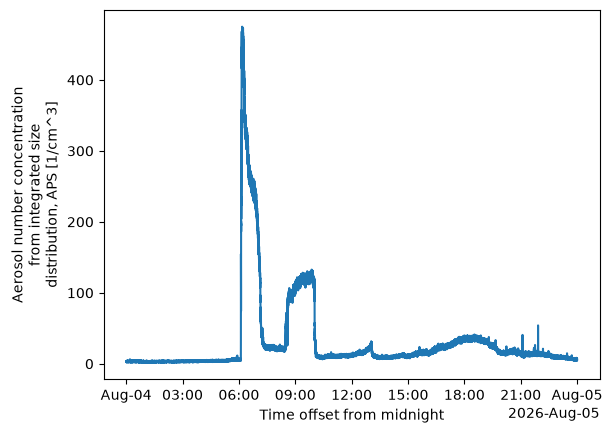

In [31]:
# Since ACT is built upon xarray, we can use xarray's built in plotting to quickly visualize the data
ds_aps['total_N_conc'].plot()

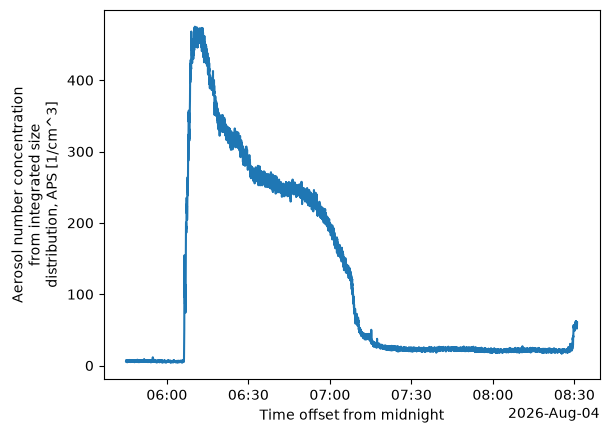

In [32]:
# We can also use xarray's built in slicing to quickly subset the data.  
# Let's look at some suspect data points in the temperature data
ds_aps['total_N_conc'].sel(time=slice('2026-08-04T05:45', '2026-08-04T08:30')).plot()

## Quality Controlling Data

ARM has multiple methods that it uses to communicate data quality information out to the users.  One of these methods is through **"embedded QC" variables**.  These are variables within the file that have information on automated tests that have been applied.  Many times, they include Min, Max, and Delta tests but as is the case with the [Aerosol Observing System (AOS)](https://armgov.svcs.arm.gov/capabilities/instruments/aos) instruments, there can be more complicated tests that are applied.

The results from all these different tests are stored in a single variable using bit-packed QC.  We won't get into the full details here, but it's a way to communicate the results of multiple tests in a single integer value by utilizing binary and bits!  You can learn more about bit-packed QC [here](https://code.arm.gov/docs/QC-flag-examples/-/wikis/home) but ACT also has many of the tools for working with ARM QC.

### Other Sources of Quality Control
ARM also communicates problems with the data quality through [Data Quality Reports (DQR)](https://dq.arm.gov/#/About).  These reports are normally submitted by the instrument mentor when there's been a problem with the instrument.  The categories include:

- **Data Quality Report Categories**
    - Missing: Data are not available or set to -9999
    - Suspect: The data are not fully incorrect but there are problems that increases the uncertainty of the values. Data should be used with caution.
    - Bad: The data are incorrect and should not be used.
    - Note: Data notes are a way to communicate information that would be useful to the end user but does not rise to the level of suspect or bad data
    
Additionally, data quality information can be found in the Instrument Handbooks, which are included on most instrument pages.  Here is an [example](https://www.arm.gov/publications/tech_reports/handbooks/met_handbook.pdf) of the MET handbook.

In [33]:
# We can see that there's some missing data in the plot above so let's take a look at the embedded QC!
# First, for many of the ACT QC features, we need to get the dataset more to CF standard and that
# involves cleaning up some of the attributes and ways that ARM has historically handled QC
ds_aps.clean.cleanup()

# Query the ARM DQR Webservice
variable = 'total_N_conc'
ds_aps = act.qc.add_dqr_to_qc(ds_aps, variable=variable)

In [34]:
ds_aps

<xarray.Dataset> Size: 49MB
Dimensions:                           (time: 86399, bound: 2,
                                       diameter_aerodynamic: 51)
Coordinates:
  * time                              (time) datetime64[ns] 691kB 2026-08-04T...
  * diameter_aerodynamic              (diameter_aerodynamic) float32 204B 0.5...
Dimensions without coordinates: bound
Data variables: (12/39)
    base_time                         datetime64[ns] 8B 2026-08-04
    time_offset                       (time) datetime64[ns] 691kB 2026-08-04T...
    time_bounds                       (time, bound) object 1MB dask.array<chunksize=(86399, 2), meta=np.ndarray>
    diameter_aerodynamic_bounds       (diameter_aerodynamic, bound) float32 408B dask.array<chunksize=(51, 2), meta=np.ndarray>
    dN_dlogDp                         (time, diameter_aerodynamic) float32 18MB dask.array<chunksize=(86399, 51), meta=np.ndarray>
    qc_dN_dlogDp                      (time, diameter_aerodynamic) int32 18MB dask.array<chunksize=(86399, 51), meta=np.ndarray>
    ...                                ...
    sheath_pump_voltage               (time) float32 346kB dask.array<chunksize=(86399,), meta=np.ndarray>
    status_flags                      (time) int32 346kB 0 0 0 0 0 ... 0 0 0 0 0
    stack_purge_state                 (time) int16 173kB 0 0 0 0 0 ... 0 0 0 0 0
    lat                               float32 4B ...
    lon                               float32 4B ...
    alt                               float32 4B ...
Attributes: (12/21)
    command_line:            aosapscorr -s dst -f M1 --max-runtime 86400
    Conventions:             ARM-1.3
    process_version:         ingest-aosapscorr-1.7-0.el9
    dod_version:             aosaps-b1-1.3
    input_datastreams:       dstaosapsM1.a0 : 1.10 : 20260804.000000\ndstaosp...
    site_id:                 dst
    ...                      ...
    doi:                     10.5439/1407135
    history:                 created by user armflowprod on machine prod-slur...
    _file_dates:             ['20260804']
    _file_times:             ['000000']
    _datastream:             dstaosapsM1.b1
    _arm_standards_flag:     1

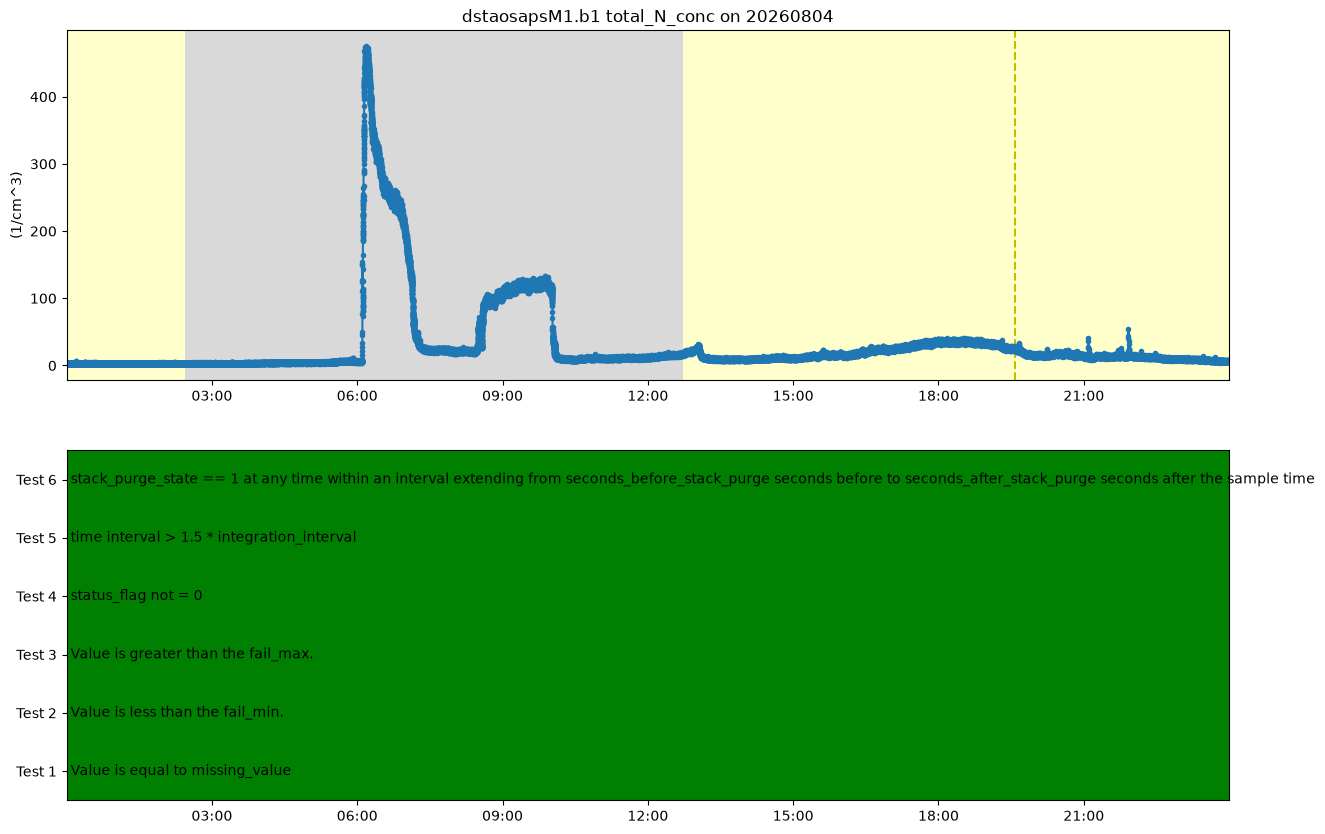

In [35]:
# Next, let's take a look at visualizing the quality control information
# Create a plotting display object with 2 plots
display = act.plotting.TimeSeriesDisplay(ds_aps, figsize=(15, 10), subplot_shape=(2,))

# Plot up the variable in the first plot
display.plot(variable, subplot_index=(0,))

# Plot up a day/night background
display.day_night_background(subplot_index=(0,))

# Plot up the QC variable in the second plot
display.qc_flag_block_plot(variable, subplot_index=(1,))
plt.show()

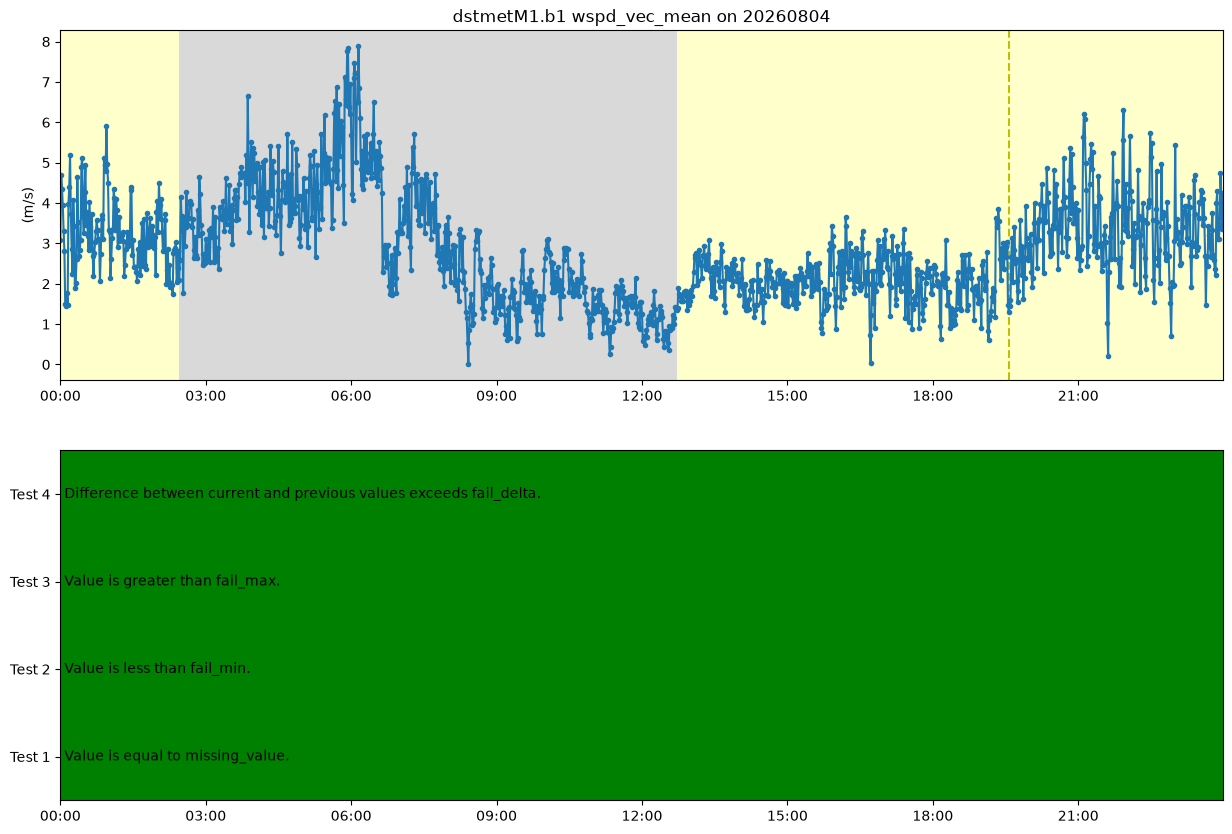

In [36]:
ds_met.clean.cleanup()
# Next, let's take a look at visualizing the quality control information
# Create a plotting display object with 2 plots
display = act.plotting.TimeSeriesDisplay(ds_met, figsize=(15, 10), subplot_shape=(2,))

# Plot up the variable in the first plot
display.plot("wspd_vec_mean", subplot_index=(0,))

# Plot up a day/night background
display.day_night_background(subplot_index=(0,))

# Plot up the QC variable in the second plot
display.qc_flag_block_plot("wspd_vec_mean", subplot_index=(1,))
plt.show()

## Visualizing Data
We've already worked with visualizing the data in basic ways but what other options are there in ACT?  This section will show you how to create a variety of different plots.  More plotting examples can be found in [ACT's Documentation](https://arm-doe.github.io/ACT/auto_examples/plotting/index.html).

### Multi-Panel Plot
This example shows how to plot multiple datastreams together (APS and the MET) on a multi-panel plot. The top panel is the APS number size distribution (`dN_dlogDp`), a 2D field (time x diameter). Since particle concentrations span several orders of magnitude and the aerodynamic diameter bins are log-spaced, we use a log-scaled colorbar and a log-scaled y-axis to keep both the fine- and coarse-mode particles visible. The bottom panel shows MET wind speed for comparison - watch for coarse-mode particle spikes that line up with wind gusts, a signature of blowing dust or haboob activity.

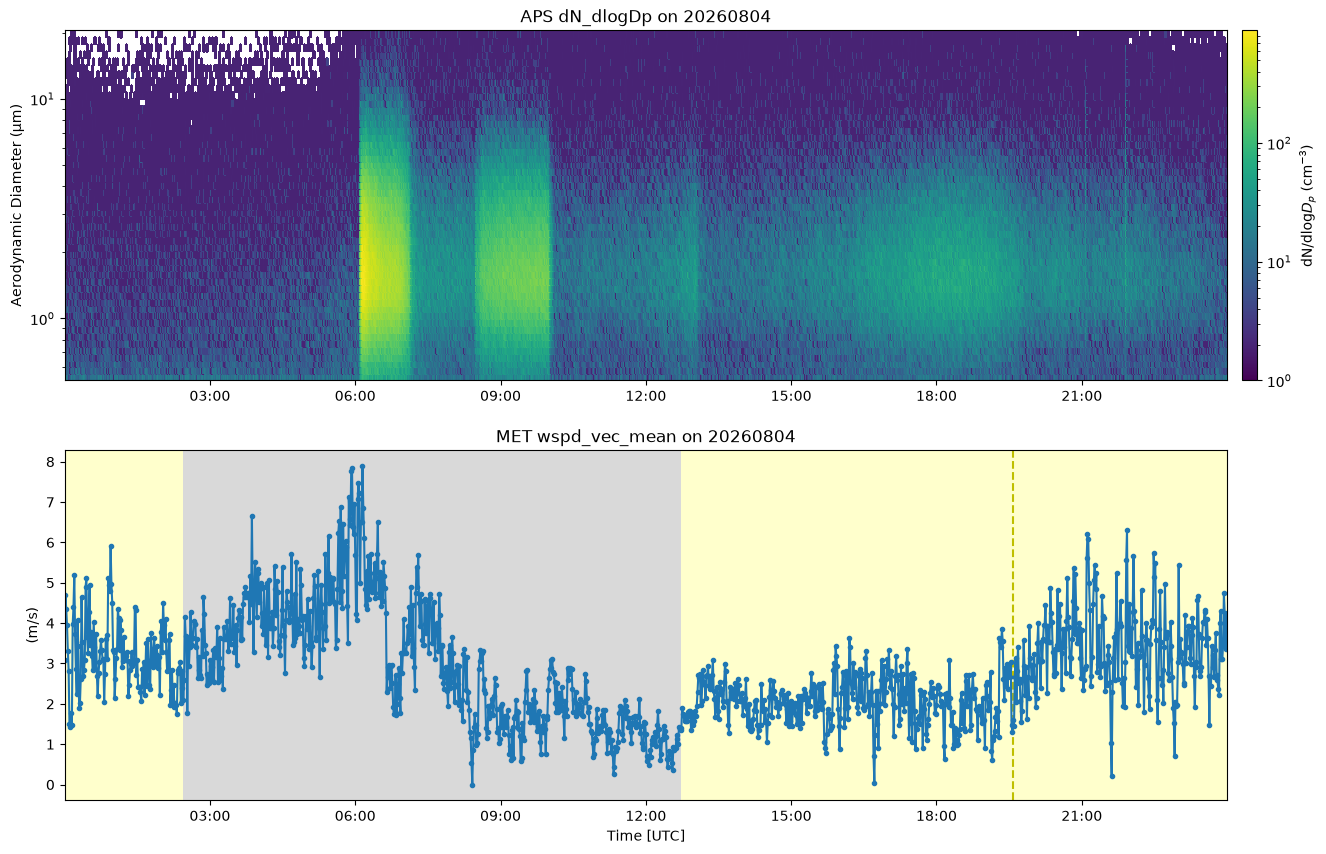

In [37]:
# And plot again!
# Create a plotting display object with 2 plots
# Note we have to create a dictionary of datasets to pass in
display = act.plotting.TimeSeriesDisplay(
    {'APS': ds_aps, 'MET': ds_met}, figsize=(15, 10), subplot_shape=(2,)
)

# LogNorm requires strictly positive values, so mask out the zero/missing
# bins before plotting rather than letting them distort the color scale
ds_aps['dN_dlogDp'] = ds_aps['dN_dlogDp'].where(ds_aps['dN_dlogDp'] > 0)

# Plot up the APS number size distribution (dN_dlogDp) as a 2D PSD.
# Need to specify the dsname so it knows which dataset to use for this
# data. This is helpful when datasets have similar variable names
display.plot(
    'dN_dlogDp',
    dsname='APS',
    subplot_index=(0,),
    cmap='viridis',
    norm=colors.LogNorm(vmin=1, vmax=float(ds_aps['dN_dlogDp'].max())),
    cbar_label=r'dN/dlog$D_p$ (cm$^{-3}$)',
    ylabel='Aerodynamic Diameter (µm)',
)
# Diameter bins are log-spaced, so a log y-axis keeps fine- and
# coarse-mode particles both visible
display.axes[0].set_yscale('log')

# Plot up the MET wind speed for comparison
display.plot('wspd_vec_mean', dsname='MET', subplot_index=(1,))

# Day/night background only makes sense on the 1D MET line plot -
# on the 2D PSD panel above it would be completely hidden behind the mesh
display.day_night_background(dsname='MET', subplot_index=(1,))

plt.show()

### Cumulative Precipitation
Another common question is how precipitation accumulates over the course of a day. ACT's `act.utils.data_utils.accumulate_precip` turns an instantaneous rain-gauge variable into a running total, which we can overlay on the original time series using a second y-axis. The DUSTIEAIM day shown here (2026-08-04) is a dust/haboob case, not a monsoon rain day, so the accumulated total stays flat at zero - a useful contrast with what this same function would show on an active North American Monsoon storm day.

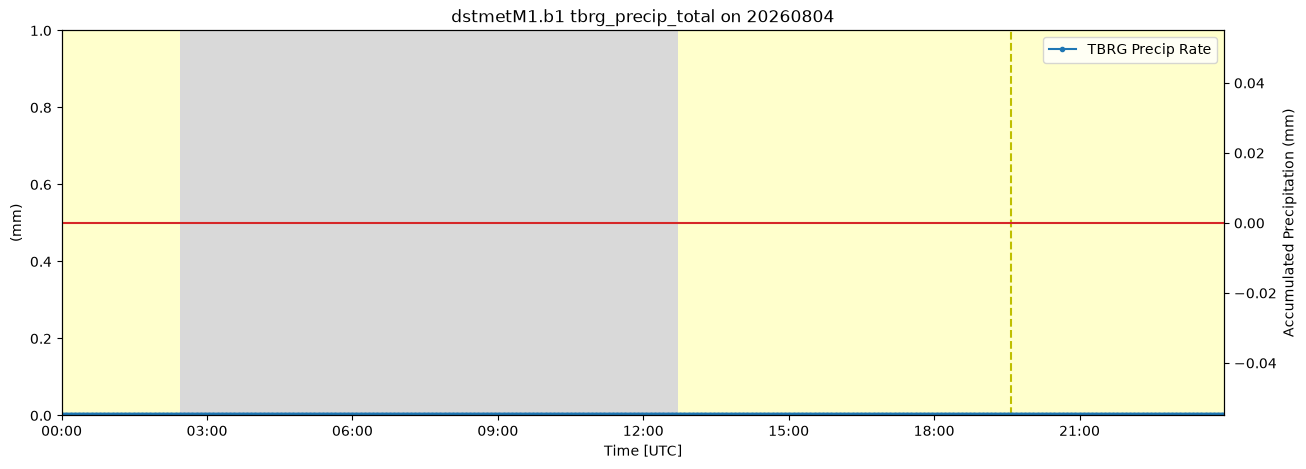

In [38]:
# ACT's accumulate_precip turns an instantaneous rain-gauge variable into a
# running total, appended to the dataset as "<variable>_accumulated"
ds_met = act.utils.data_utils.accumulate_precip(ds_met, 'tbrg_precip_total')

# Plot the instantaneous rate on the left axis and the running total on a
# twin axis so both are visible on the same time base
display = act.plotting.TimeSeriesDisplay(ds_met, figsize=(15, 5))
display.plot('tbrg_precip_total', label='TBRG Precip Rate')

ax2 = display.axes[0].twinx()
ax2.plot(ds_met['time'], ds_met['tbrg_precip_total_accumulated'], color='tab:red')
ax2.set_ylabel('Accumulated Precipitation (mm)')

display.day_night_background()
plt.show()

### Adding the Doppler Lidar

The multi-panel plot above pairs the aerosol size distribution with near-surface wind speed, but it says nothing about what the air is doing *above* the station. The Doppler lidar fills that gap. In fixed-point mode the beam stares straight up, so the measured `radial_velocity` is the vertical air motion - positive away from the instrument (upward), negative toward it (downward).

The lidar samples about once a second over 400 range gates, so a full day is a lot of data for one figure. We downloaded only the 05-09 UTC window above, and we narrow the APS and MET to the same window here so all three panels share a time axis. Two more things are worth doing before plotting:

1. **Screen on signal strength.** The lidar needs aerosol to scatter from, so the returns go to noise above the aerosol layer. The `intensity` variable is signal-to-noise ratio + 1, and a threshold of around 1.01 is a common cutoff for keeping trustworthy velocities.
1. **Trim the range.** The files extend to roughly 12 km, but on this day the usable signal is almost entirely below 2 km, so we subset to the boundary layer.

The result is a three-panel view of the dust event: aerosol size distribution on top, vertical velocity in the middle, and surface wind speed on the bottom. Three things line up. The surface wind ramps up through 05:30-06:10, the lidar shows a band of strong upward motion in that same half hour, and then just after 06:10 the APS concentration jumps across every size bin as the dust reaches the station. Notice what happens to the lidar panel at that moment: the returns above roughly 1 km drop below the intensity threshold and white out, which is what you expect when a dense aerosol layer near the surface attenuates the beam before it gets any higher.

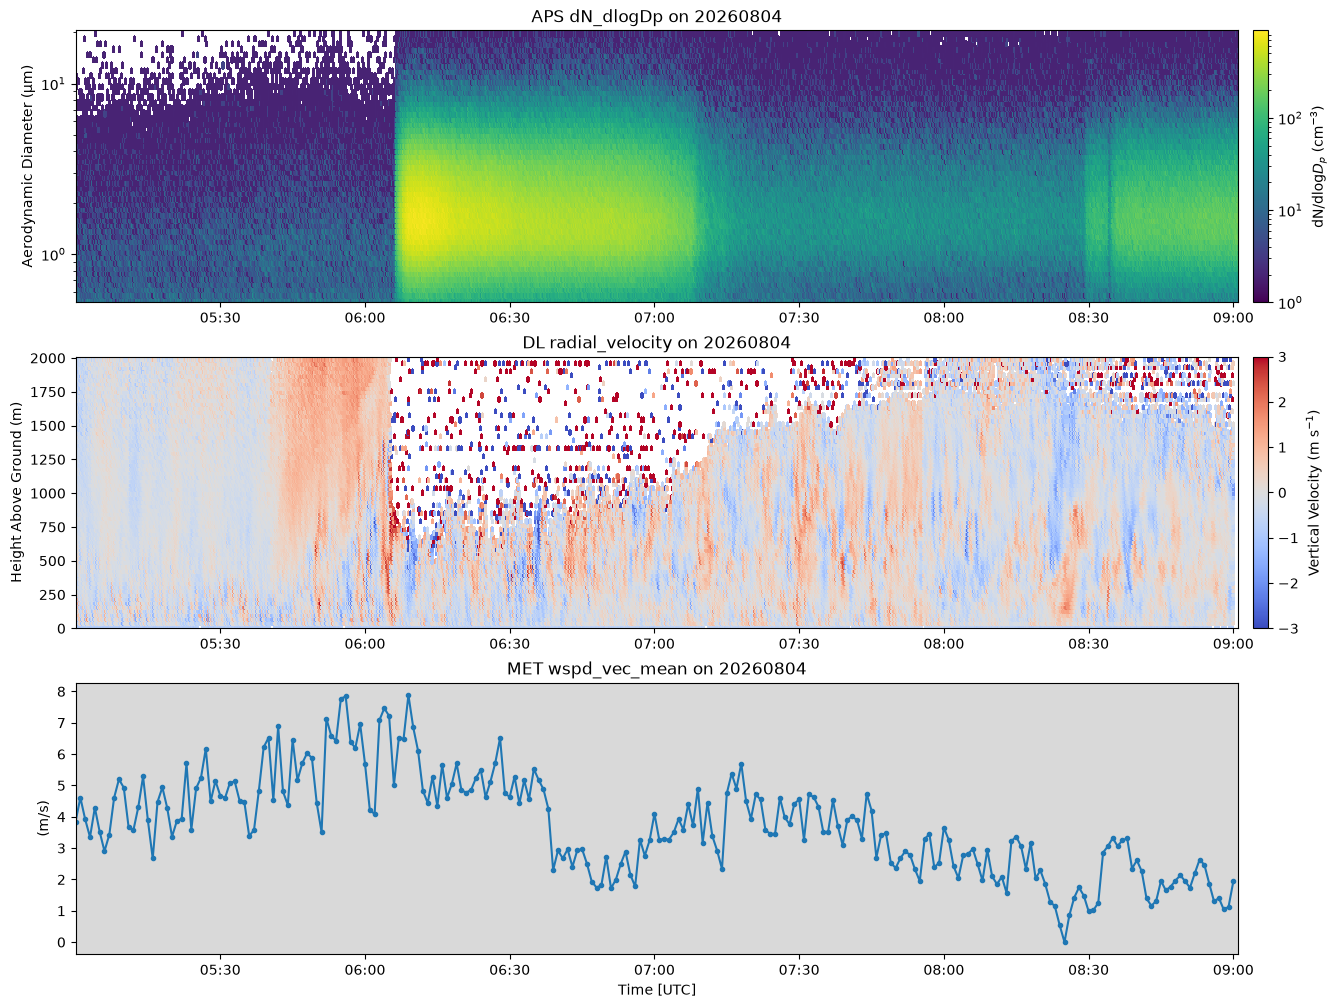

In [39]:
# Narrow every dataset to the same window so the three panels line up
plot_start = '2026-08-04T05:00'
plot_end = '2026-08-04T09:00'

ds_aps_sub = ds_aps.sel(time=slice(plot_start, plot_end))
ds_met_sub = ds_met.sel(time=slice(plot_start, plot_end))

# The lidar needs aerosol to scatter from, so returns above the aerosol layer are
# noise.  Screen on intensity (signal-to-noise ratio + 1) and trim to the
# boundary layer, where the signal actually lives
ds_dl_sub = ds_dl.sel(time=slice(plot_start, plot_end), range=slice(0, 2000))
ds_dl_sub['radial_velocity'] = ds_dl_sub['radial_velocity'].where(
    ds_dl_sub['intensity'] > 1.01
)

# Three datasets this time, passed in the same dictionary style as before
display = act.plotting.TimeSeriesDisplay(
    {'APS': ds_aps_sub, 'DL': ds_dl_sub, 'MET': ds_met_sub},
    figsize=(15, 12),
    subplot_shape=(3,),
)

# Top panel - the APS number size distribution, same as the multi-panel plot above
display.plot(
    'dN_dlogDp',
    dsname='APS',
    subplot_index=(0,),
    cmap='viridis',
    norm=colors.LogNorm(vmin=1, vmax=float(ds_aps_sub['dN_dlogDp'].max())),
    cbar_label=r'dN/dlog$D_p$ (cm$^{-3}$)',
    ylabel='Aerodynamic Diameter (µm)',
)
display.axes[0].set_yscale('log')

# Middle panel - vertical velocity.  Use a diverging colormap centered on zero so
# updrafts and downdrafts are easy to tell apart, and clip the range so the
# everyday turbulence isn't washed out by a handful of extreme values
display.plot(
    'radial_velocity',
    dsname='DL',
    subplot_index=(1,),
    cmap='coolwarm',
    vmin=-3,
    vmax=3,
    cbar_label='Vertical Velocity (m s$^{-1}$)',
    ylabel='Height Above Ground (m)',
)

# Bottom panel - surface wind speed from the MET
display.plot('wspd_vec_mean', dsname='MET', subplot_index=(2,))
display.day_night_background(dsname='MET', subplot_index=(2,))

plt.show()

### Combining Datasets

The plots so far have kept each datastream separate. Some of ACT's displays, though, want a single dataset holding every variable they are asked for - the data rose below is one of them, since it needs wind direction and wind speed from the MET alongside particle concentration from the APS. The two instruments report on different time bases, so we resample both onto a common one-minute grid before merging.

In [40]:
# Before the two datasets can be merged, they need to share a time grid
# Once again, we take advantage of the xarray data structures and use xarray's resample function
ds_aps = ds_aps.resample(time='1Min').nearest()
ds_met = ds_met.resample(time='1Min').nearest()

<div class="admonition alert alert-info">
    <p class="admonition-title" style="font-weight:bold">More Information on Combining Data with Xarray</p>
    Find more information on combining data with xarray <a href="https://docs.xarray.dev/en/stable/user-guide/combining.html" style="font-weight:bold" target="_blank">[here]</a>
</div>

In [41]:
# Combine the datasets together using xarray's merge function.
ds_combined = xr.merge([ds_aps, ds_met], compat='override')

ds_combined

<xarray.Dataset> Size: 1MB
Dimensions:                           (time: 1440, diameter_aerodynamic: 51,
                                       bound: 2)
Coordinates:
  * time                              (time) datetime64[ns] 12kB 2026-08-04 ....
  * diameter_aerodynamic              (diameter_aerodynamic) float32 204B 0.5...
Dimensions without coordinates: bound
Data variables: (12/83)
    base_time                         datetime64[ns] 8B 2026-08-04
    time_offset                       (time) datetime64[ns] 12kB 2026-08-04T0...
    time_bounds                       (time, bound) object 23kB dask.array<chunksize=(1440, 2), meta=np.ndarray>
    diameter_aerodynamic_bounds       (diameter_aerodynamic, bound) float32 408B dask.array<chunksize=(51, 2), meta=np.ndarray>
    dN_dlogDp                         (time, diameter_aerodynamic) float32 294kB dask.array<chunksize=(1440, 51), meta=np.ndarray>
    qc_dN_dlogDp                      (time, diameter_aerodynamic) int32 294kB dask.array<chunksize=(1440, 51), meta=np.ndarray>
    ...                                ...
    qc_pwd_cumul_snow                 (time) int32 6kB dask.array<chunksize=(1440,), meta=np.ndarray>
    logger_volt                       (time) float32 6kB dask.array<chunksize=(1440,), meta=np.ndarray>
    qc_logger_volt                    (time) int32 6kB dask.array<chunksize=(1440,), meta=np.ndarray>
    logger_temp                       (time) float32 6kB dask.array<chunksize=(1440,), meta=np.ndarray>
    qc_logger_temp                    (time) int32 6kB dask.array<chunksize=(1440,), meta=np.ndarray>
    tbrg_precip_total_accumulated     (time) float32 6kB 0.0 0.0 0.0 ... 0.0 0.0
Attributes: (12/21)
    command_line:            aosapscorr -s dst -f M1 --max-runtime 86400
    Conventions:             ARM-1.3
    process_version:         ingest-aosapscorr-1.7-0.el9
    dod_version:             aosaps-b1-1.3
    input_datastreams:       dstaosapsM1.a0 : 1.10 : 20260804.000000\ndstaosp...
    site_id:                 dst
    ...                      ...
    doi:                     10.5439/1407135
    history:                 created by user armflowprod on machine prod-slur...
    _file_dates:             ['20260804']
    _file_times:             ['000000']
    _datastream:             dstaosapsM1.b1
    _arm_standards_flag:     1

### Data Rose Plots

If your data may be wind speed or direction dependent, these plots can help inform where the influences may be coming from (or confirm there are no blocking QC issues).  For this example, let's see if tipping bucket rain guage data are dependent on wind direction

/Users/jrobrien/miniforge3/envs/arm-tutorial-dev/lib/python3.14/site-packages/act/plotting/windrosedisplay.py:358: RuntimeWarning: Mean of empty slice
  arr.append(np.nanmean(data[idx]))


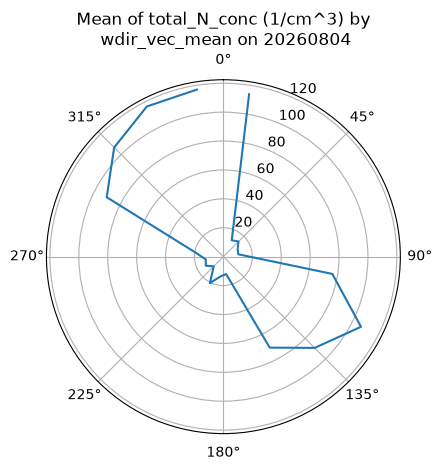

In [42]:
# Plot out the data rose using the WindRose display object
display = act.plotting.WindRoseDisplay(ds_combined)
display.plot_data('wdir_vec_mean', 'wspd_vec_mean', 'total_N_conc', num_dirs=20, plot_type='line', line_plot_calc='mean')
plt.show()

/Users/jrobrien/miniforge3/envs/arm-tutorial-dev/lib/python3.14/site-packages/act/plotting/windrosedisplay.py:429: RuntimeWarning: Mean of empty slice
  mean_data[i, j] = np.nanmean(data[idx])


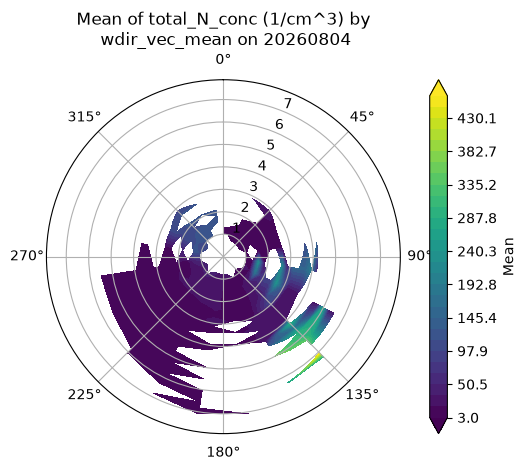

In [43]:
# Plot out the data rose using the WindRose display object
display = act.plotting.WindRoseDisplay(ds_combined)

# Let's try a different type of data rose type that is using contours amd the polar y axis is wind speed
# depending on wind direction and speed
display.plot_data('wdir_vec_mean', 'wspd_vec_mean', 'total_N_conc', num_dirs=20, plot_type='contour', contour_type='mean')
plt.show()

---

## Challenge Problems

<div class="admonition alert alert-success">
    <p class="admonition-title" style="font-weight:bold">Question 1</p>
    There have been many dust storms that have impacted DUSTIEAIM. Update this analysis to compare the 11 August 2026 and 20 August 2026 events at the M1 facility. 
</div>

<div class="admonition alert alert-warning">
    <p class="admonition-title" style="font-weight:bold">Question 2</p>
    The doppler lidar was unable to capture the full vertical extent of the 4 August 2026 dust plume. Use ACT to download, correct and analyze the micropulse lidar observations for this event. What was the vertical profile of the storm?
</div>

---